In [1]:
import os
os.chdir("..")  # run only once, or the path will move up again on a re-run

In [2]:
import sys
sys.path.append("..")  

import pandas as pd
from src.data.loader import load_documents
from src.data.chunker import chunk_documents

docs = load_documents()
chunks = chunk_documents(docs)

doc_df = pd.DataFrame(
    [{"source": d.source, "department": d.department, "title": d.title,
      "words": len(d.text.split())} for d in docs]
)
chunk_df = pd.DataFrame(
    [{"chunk_id": c.chunk_id, "department": c.department, "section": c.section,
      "words": len(c.text.split())} for c in chunks]
)
len(doc_df), len(chunk_df)

(351, 4480)

In [3]:
doc_df.groupby("department").agg(
    docs=("source", "count"), total_words=("words", "sum"), median_words=("words", "median")
)

,docs,total_words,median_words
department,,,
engineering,60,71113,594.5
finance,51,88626,1180.0
legal,60,162806,1571.5
people-group,60,126177,1232.5
security,60,44543,529.5
support,60,63052,730.5


<Axes: >

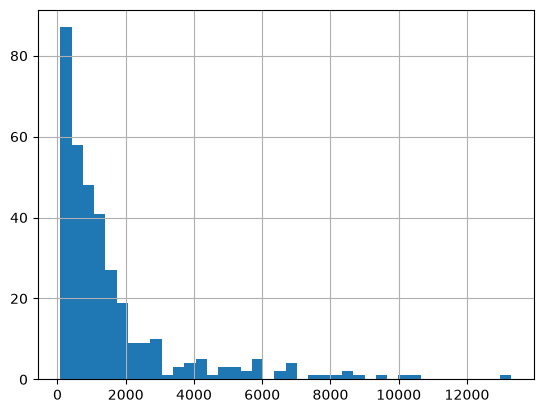

In [4]:
doc_df["words"].describe()
doc_df["words"].hist(bins=40)

department
engineering      717
finance          711
legal           1001
people-group    1051
security         400
support          600
dtype: int64

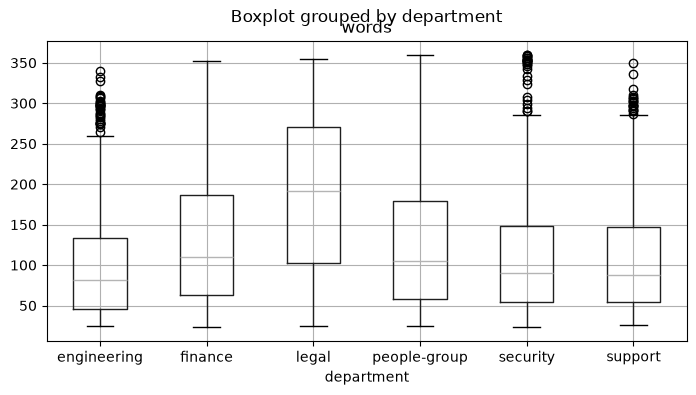

In [5]:
chunk_df.boxplot(column="words", by="department", figsize=(8, 4))
chunk_df.groupby("department").size()

### Legal texts are much longer than the others

In [6]:
chunk_df["source"] = chunk_df["chunk_id"].str.split("::").str[0]
chunk_df.groupby("source").size().describe()

count    344.000000
mean      13.023256
std       15.338913
min        1.000000
25%        4.000000
50%        8.000000
75%       15.000000
max      153.000000
dtype: float64

In [7]:
chunk_df["section"].value_counts().head(20)

section
                                                            131
Overview                                                     82
1. DEFINITIONS                                               53
6. PAYMENT OF FEES                                           27
5. RESTRICTIONS AND RESPONSIBILITIES                         23
10. INDEMNIFICATION                                          21
CorpSec Systems Directory                                    21
7. CONFIDENTIALITY                                           20
14. SECURITY / DATA PROTECTION                               16
Parameters                                                   15
Introduction                                                 14
8. INTELLECTUAL PROPERTY RIGHTS                              12
15. MISCELLANEOUS                                            12
Purpose                                                      11
Slack                                                        10
Scope                           

In [8]:
import random
for c in random.sample(chunks, 3):
    print(c.department, "|", c.chunk_id)
    print(c.text[:700])
    print("-" * 60)

people-group | employment-branding__content-library.md::2
Content library - life at GitLab > Key messages about life at GitLab

- We're one of the largest all-remote companies in the world, and we've intentionally built our culture this way from our founding year.
- Our mission makes it clear that we believe in a world where everyone can contribute. We make that possible at GitLab by running our operations on our product and staying aligned with our values​ in everything we do.
- More about [life at GitLab and our culture](/handbook/company/culture/).
------------------------------------------------------------
finance | accounting___index.md::44
Accounting and Reporting > Property, Plant and Equipment

Property, plant and equipment is the long-term asset or noncurrent asset section of the balance sheet. Following are the sub-processes:
------------------------------------------------------------
legal | esg__earth-month___index.md::4
Earth Month > Important Volunteering Notes

- When 

### We can see some artifacts are still left so loader should be improved

In [10]:
raw_words = doc_df["words"].sum()
kept_words = chunk_df["words"].sum()
raw_words, kept_words

(np.int64(556317), np.int64(600015))

In [11]:
import random
import numpy as np
from src.retrieval.embedder import embed_documents

random.seed(42)
sample = random.sample(chunks, 1000)
vectors = np.array(embed_documents([c.text for c in sample]))
labels = [c.department for c in sample]
vectors.shape

c:\Users\antek\LLM-assistant-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1102 12:50:08.685000 10640 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Batches: 100%|██████████| 16/16 [00:08<00:00,  1.89it/s]


(1000, 1024)

In [12]:
from sklearn.manifold import TSNE

coords = TSNE(
    n_components=2, perplexity=30, metric="cosine", init="pca", random_state=42
).fit_transform(vectors)
coords.shape

(1000, 2)

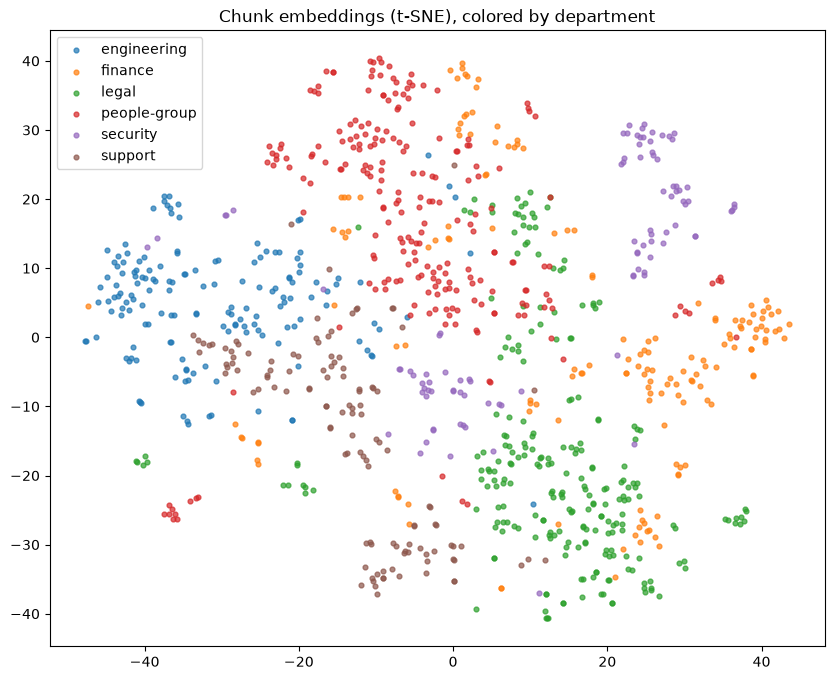

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
for dept in sorted(set(labels)):
    idx = [i for i, l in enumerate(labels) if l == dept]
    plt.scatter(coords[idx, 0], coords[idx, 1], s=12, alpha=0.7, label=dept)
plt.legend()
plt.title("Chunk embeddings (t-SNE), colored by department")
plt.show()

### Support documents have quite a bit of overlap with security, other than that the clusters are formed by departments, with some outliers